# Gamma, meditation experience and age

The paper reports that parieto-occipital gamma (60–110 Hz, MED and IMW combined) is higher in meditators than controls,
and that among meditators it correlates with log lifetime practice hours (Fig. 4D: skipped Pearson $r = 0.33$,
95% CI [0.06, 0.53]). This notebook:

1. checks how age is distributed across groups (matched sample vs the full dataset);
2. replicates Fig. 4D from the paper's own per-subject values (Zenodo);
3. tests whether age explains the experience correlation;
4. tests whether age explains the meditator–control gamma difference;
5. repeats the key tests on this replication's own gamma values (no ICA and capped ICA).

Data: `mw_medit_combined_parieto_occip_Gamma_correl_exp.csv` from Zenodo (doi 10.5281/zenodo.57911) has, per subject
of the paper's 64, lifetime meditation hours, age, the combined MED+IMW parieto-occipital gamma used for Fig. 4D
(the same values as `Combined_Post` in `median_gamma_power.csv`), and self-rated meditation depth.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy import stats
from sklearn.covariance import MinCovDet

ROOT = Path.cwd().parent
ZENODO = Path('/home/jackhoyle/mne_data/braboszcz_zenodo_57911')
BIDS = Path('/home/jackhoyle/mne_data/ds003969')
COLOURS = {'CTR': '#2a78d6', 'HYT': '#eb6834', 'ISY': '#1baf7a', 'VIP': '#eda100'}
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 9})
warnings.simplefilter('ignore', FutureWarning)

## Data

In [2]:
# the paper's per-subject values (64 subjects, lab IDs)
zen = pd.read_csv(ZENODO / 'mw_medit_combined_parieto_occip_Gamma_correl_exp.csv').rename(columns={
    'Sujet': 'lab_id', 'Type': 'group', 'Meditation Expe': 'hours', 'Age': 'age', 'Median Gamma': 'gamma_paper',
    'Depth Med': 'depth'})
zen['meditator'] = (zen.group != 'CTR').astype(int)
zen['log_hours'] = np.log10(zen.hours.where(zen.hours > 0))

# lab ID -> ds003969 subject (HYT26 is not in ds003969), and dataset demographics
mapping = pd.read_csv(ROOT / 'writeup/results/paper_included_subjects.csv')
participants = pd.read_csv(BIDS / 'participants.tsv', sep='\t')
participants['subject'] = participants.participant_id.str.removeprefix('sub-')
zen = zen.merge(mapping[['lab_id', 'participant_id']], on='lab_id', how='left')
zen['subject'] = zen.participant_id.str.removeprefix('sub-')
zen = zen.merge(participants[['subject', 'gender', 'age', 'years_of_practice']].rename(columns={'age': 'age_bids'}),
                on='subject', how='left')

# the paper's ages agree with the dataset's for all 63 mapped subjects
assert (zen.dropna(subset=['subject']).eval('age == age_bids')).all()
print(zen.groupby('group')[['age', 'hours', 'depth']].agg(['mean', 'std']).round(1))
print('\nlog hours vs years_of_practice (dataset), Spearman:',
      round(stats.spearmanr(zen.hours, zen.years_of_practice, nan_policy='omit')[0], 2))

        age          hours          depth     
       mean   std     mean      std  mean  std
group                                         
CTR    45.4  10.3      0.0      0.0   0.0  0.0
HYT    48.6  14.7  15475.2  12588.7   6.3  1.9
ISY    40.1  10.3   2625.8   2607.3   7.6  1.1
VIP    46.8  14.6   9201.8   7759.5   6.0  1.8

log hours vs years_of_practice (dataset), Spearman: 0.9


## 1. Are the controls younger?

Not in the paper's matched sample: controls average 45 years, the same as the meditators as a whole. The young controls
were the 15 that the paper left out, which an earlier full-sample analysis included.

In [3]:
matched = set(mapping.loc[mapping.in_dataset, 'participant_id'])
p = participants[participants.group != 'tm'].assign(
    sample=lambda d: np.where(d.participant_id.isin(matched), 'matched (paper)', 'excluded by paper'),
    group=lambda d: d.group.str.upper().replace({'HTR': 'HYT', 'SNY': 'ISY'}))
age_table = p.pivot_table(index='group', columns='sample', values='age', aggfunc=['mean', 'count']).round(1)
age_table.loc['all meditators'] = [
    p[(p.group != 'CTR') & (p['sample'] == s)].age.mean().round(1) for s in age_table['mean'].columns] + [
    (p[(p.group != 'CTR') & (p['sample'] == s)]).shape[0] for s in age_table['count'].columns]
print(age_table)
print('\nMatched sample, controls vs meditators (Welch t):',
      stats.ttest_ind(zen[zen.group == 'CTR'].age, zen[zen.group != 'CTR'].age, equal_var=False))

                            mean                             count  \
sample         excluded by paper matched (paper) excluded by paper   
group                                                                
CTR                         33.8            45.4              15.0   
HYT                         55.2            47.9               9.0   
ISY                         31.5            40.1               4.0   
VIP                         56.0            46.8               3.0   
all meditators              49.4            44.9              16.0   

                                
sample         matched (paper)  
group                           
CTR                       16.0  
HYT                       15.0  
ISY                       16.0  
VIP                       16.0  
all meditators            47.0  

Matched sample, controls vs meditators (Welch t): TtestResult(statistic=np.float64(0.08392021171442048), pvalue=np.float64(0.9336146606900727), df=np.float64(33.8196259401104

## 2. Replicating Fig. 4D

Skipped correlation as in Pernet, Wilcox and Rousselet (2013), which the paper used: bivariate outliers are found
with the projection method (robust centre from the minimum covariance determinant, boxplot rule with ideal fourths),
removed, and Pearson's $r$ computed on the rest. 95% CIs are percentile bootstraps (2000 resamples), redoing the
outlier detection in each resample.

In [4]:
def _ideal_fourths(x):
    n = len(x)
    j = int(np.floor(n / 4 + 5 / 12))
    y = np.sort(x)
    g = n / 4 - j + 5 / 12
    low = (1 - g) * y[j - 1] + g * y[j]
    k = n - j + 1
    up = (1 - g) * y[k - 1] + g * y[k - 2]
    return up - low


def skipped_outliers(x, y, seed=42):
    """Boolean mask of bivariate outliers (projection method, Wilcox 2012; as in Pernet et al. 2013)."""
    X = np.column_stack([x, y])
    centre = MinCovDet(random_state=seed).fit(X).location_
    B = X - centre
    bot = (B ** 2).sum(axis=1)
    dis = np.zeros((len(X), len(X)))
    for i in range(len(X)):
        if bot[i] != 0:
            dis[i] = np.linalg.norm(np.outer(B @ B[i], B[i]) / bot[i], axis=1)
    gval = np.sqrt(stats.chi2.ppf(0.975, 2))
    out = np.zeros(len(X), bool)
    for i in range(len(X)):
        out |= dis[i] > np.median(dis[i]) + gval * _ideal_fourths(dis[i])
    return out


def skipped_corr(x, y, n_boot=2000, seed=0):
    x, y = np.asarray(x, float), np.asarray(y, float)
    out = skipped_outliers(x, y)
    r = stats.pearsonr(x[~out], y[~out])[0]
    rng = np.random.default_rng(seed)
    boots = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(x), len(x))
        try:
            o = skipped_outliers(x[idx], y[idx])
            boots.append(stats.pearsonr(x[idx][~o], y[idx][~o])[0])
        except Exception:  # degenerate resample
            continue
    lo, hi = np.percentile(boots, [2.5, 97.5])
    return dict(r=r, ci_low=lo, ci_high=hi, n=len(x), n_outliers=int(out.sum()), outliers=out)


def describe(x, y, label):
    """Pearson, Spearman and skipped correlation in one row."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    pr, pp = stats.pearsonr(x, y)
    sr, sp = stats.spearmanr(x, y)
    sk = skipped_corr(x, y)
    return dict(label=label, n=len(x), pearson_r=pr, pearson_p=pp, spearman_rho=sr, spearman_p=sp,
                skipped_r=sk['r'], skipped_ci=f"[{sk['ci_low']:.2f}, {sk['ci_high']:.2f}]",
                skipped_outliers=sk['n_outliers'])

In [5]:
med = zen[zen.meditator == 1].copy()
fig4d = skipped_corr(med.log_hours, med.gamma_paper)
print(f"Skipped r = {fig4d['r']:.2f}, 95% CI [{fig4d['ci_low']:.2f}, {fig4d['ci_high']:.2f}], "
      f"n = {fig4d['n']}, outliers removed = {fig4d['n_outliers']}  (paper: r = 0.33, CI [0.06, 0.53])")
print('Outliers:', med.loc[fig4d['outliers'], ['lab_id', 'hours', 'gamma_paper']].to_dict('records'))
pd.DataFrame([describe(med.log_hours, med.gamma_paper, 'gamma vs log hours, meditators (paper values)')]).round(3)

Skipped r = 0.33, 95% CI [-0.15, 0.50], n = 48, outliers removed = 2  (paper: r = 0.33, CI [0.06, 0.53])
Outliers: [{'lab_id': 'HYT7', 'hours': 20353.5, 'gamma_paper': 24.3412}, {'lab_id': 'ISY6', 'hours': 576.25, 'gamma_paper': 40.8231}]


,label,n,pearson_r,pearson_p,spearman_rho,spearman_p,skipped_r,skipped_ci,skipped_outliers
0,"gamma vs log hours, meditators (paper values)",48,0.164,0.265,0.143,0.331,0.332,"[-0.15, 0.50]",2


### Bootstrap with the outliers fixed

The CI above redoes the outlier detection in every resample. An alternative is to remove the two outliers once and
bootstrap Pearson's $r$ on the remaining 46 meditators. Two versions:
- a plain percentile bootstrap (2000 resamples);
- Wilcox's adjusted percentile bootstrap for Pearson's $r$ (599 resamples, with the cut-off order statistics
  depending on $n$), which robust-correlation toolboxes such as Pernet's may use.

In [6]:
def boot_pearson(x, y, n_boot, seed=0):
    rng = np.random.default_rng(seed)
    x, y = np.asarray(x, float), np.asarray(y, float)
    idx = rng.integers(0, len(x), (n_boot, len(x)))
    return np.array([stats.pearsonr(x[i], y[i])[0] for i in idx])


def wilcox_adjusted_ci(x, y, seed=0):
    """Wilcox (2012) adjusted percentile bootstrap for Pearson's r: 599 resamples, sorted, with the CI bounds
    taken at order statistics that depend on n."""
    b = np.sort(boot_pearson(x, y, 599, seed))
    n = len(x)
    lo, hi = (7, 593) if n < 40 else (8, 592) if n < 80 else (11, 588) if n < 180 else (14, 585) if n < 250 else (15, 584)
    return b[lo - 1], b[hi - 1]


keep = ~fig4d['outliers']
xk, yk = med.log_hours.values[keep], med.gamma_paper.values[keep]
plain = np.percentile(boot_pearson(xk, yk, 2000), [2.5, 97.5])
adj = wilcox_adjusted_ci(xk, yk)
pd.DataFrame([
    dict(method='outliers redetected in each resample (above)', r=fig4d['r'], ci_low=fig4d['ci_low'], ci_high=fig4d['ci_high']),
    dict(method='outliers removed once, percentile (2000)', r=fig4d['r'], ci_low=plain[0], ci_high=plain[1]),
    dict(method='outliers removed once, Wilcox adjusted (599)', r=fig4d['r'], ci_low=adj[0], ci_high=adj[1]),
    dict(method='paper', r=0.33, ci_low=0.06, ci_high=0.53),
]).round(2)

,method,r,ci_low,ci_high
0,outliers redetected in each resample (above),0.33,-0.15,0.50
1,"outliers removed once, percentile (2000)",0.33,0.07,0.54
2,"outliers removed once, Wilcox adjusted (599)",0.33,0.05,0.59
3,paper,0.33,0.06,0.53


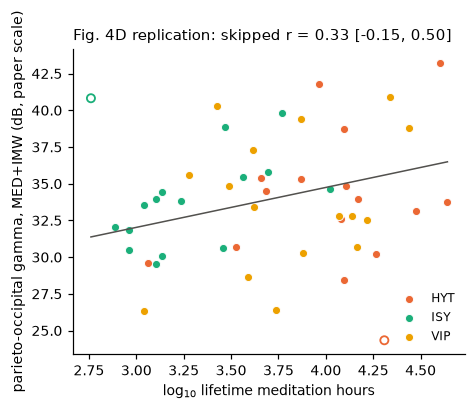

In [7]:
fig, ax = plt.subplots(figsize=(4.6, 3.6))
for g, d in med.groupby('group'):
    o = fig4d['outliers'][med.group.values == g]
    ax.scatter(d.log_hours[~o], d.gamma_paper[~o], s=28, color=COLOURS[g], edgecolor='white', lw=0.6, label=g)
    ax.scatter(d.log_hours[o], d.gamma_paper[o], s=28, facecolor='none', edgecolor=COLOURS[g], lw=1.2)
keep = ~fig4d['outliers']
slope, intercept = np.polyfit(med.log_hours[keep], med.gamma_paper[keep], 1)
xs = np.linspace(med.log_hours.min(), med.log_hours.max(), 50)
ax.plot(xs, intercept + slope * xs, color='#52514e', lw=1)
ax.set_xlabel('log$_{10}$ lifetime meditation hours')
ax.set_ylabel('parieto-occipital gamma, MED+IMW (dB, paper scale)')
ax.set_title(f"Fig. 4D replication: skipped r = {fig4d['r']:.2f} "
             f"[{fig4d['ci_low']:.2f}, {fig4d['ci_high']:.2f}]", loc='left', fontsize=9.5)
ax.legend(frameon=False, fontsize=8)
plt.show()

## 3. Does age explain the experience correlation?

Practice hours accumulate with age, so a gamma–age relationship among meditators would produce a gamma–hours
correlation on its own. Three checks: the pairwise correlations, a regression with both predictors, and the same
with tradition fixed effects (the traditions differ a lot in typical hours).

In [8]:
pd.DataFrame([
    describe(med.log_hours, med.gamma_paper, 'gamma vs log hours, meditators'),
    describe(med.age, med.gamma_paper, 'gamma vs age, meditators'),
    describe(med.age, med.log_hours, 'log hours vs age, meditators'),
    describe(zen[zen.group == 'CTR'].age, zen[zen.group == 'CTR'].gamma_paper, 'gamma vs age, controls'),
]).round(3)

,label,n,pearson_r,pearson_p,spearman_rho,spearman_p,skipped_r,skipped_ci,skipped_outliers
0,"gamma vs log hours, meditators",48,0.164,0.265,0.143,0.331,0.332,"[-0.15, 0.50]",2
1,"gamma vs age, meditators",48,0.266,0.068,0.236,0.106,0.266,"[-0.09, 0.57]",0
2,"log hours vs age, meditators",48,0.376,0.009,0.398,0.005,0.376,"[0.11, 0.61]",0
3,"gamma vs age, controls",16,-0.528,0.036,-0.501,0.048,-0.528,"[-0.82, 0.07]",0


In [9]:
def zscore(s):
    return (s - s.mean()) / s.std()


medz = med.assign(gamma_z=zscore(med.gamma_paper), log_hours_z=zscore(med.log_hours), age_z=zscore(med.age))
models = {
    'hours only': 'gamma_z ~ log_hours_z',
    'age only': 'gamma_z ~ age_z',
    'hours + age': 'gamma_z ~ log_hours_z + age_z',
    'hours + age + tradition': 'gamma_z ~ log_hours_z + age_z + C(group)',
}
rows = []
for name, f in models.items():
    fit = smf.ols(f, medz).fit(cov_type='HC3')
    for term in ['log_hours_z', 'age_z']:
        if term in fit.params:
            rows.append(dict(model=name, term=term, beta=fit.params[term], se=fit.bse[term], p=fit.pvalues[term],
                             r2=fit.rsquared))
print('Standardised coefficients (OLS, HC3 SEs), meditators n =', len(medz))
pd.DataFrame(rows).round(3)

Standardised coefficients (OLS, HC3 SEs), meditators n = 48


,model,term,beta,se,p,r2
0,hours only,log_hours_z,0.164,0.169,0.333,0.027
1,age only,age_z,0.266,0.162,0.102,0.071
2,hours + age,log_hours_z,0.075,0.188,0.689,0.075
3,hours + age,age_z,0.237,0.195,0.224,0.075
4,hours + age + tradition,log_hours_z,0.238,0.198,0.229,0.113
5,hours + age + tradition,age_z,0.246,0.207,0.235,0.113


In [10]:
# partial correlations of gamma with log hours controlling for age, and with age controlling for log hours
def partial(df, x, y, covar):
    rx = smf.ols(f'{x} ~ {covar}', df).fit().resid
    ry = smf.ols(f'{y} ~ {covar}', df).fit().resid
    return describe(rx, ry, f'{y} ~ {x} | {covar}')


pd.DataFrame([partial(med, 'log_hours', 'gamma_paper', 'age'),
              partial(med, 'age', 'gamma_paper', 'log_hours')]).round(3)

,label,n,pearson_r,pearson_p,spearman_rho,spearman_p,skipped_r,skipped_ci,skipped_outliers
0,gamma_paper ~ log_hours | age,48,0.072,0.626,0.043,0.771,0.072,"[-0.27, 0.42]",0
1,gamma_paper ~ age | log_hours,48,0.223,0.128,0.208,0.155,0.307,"[-0.22, 0.59]",1


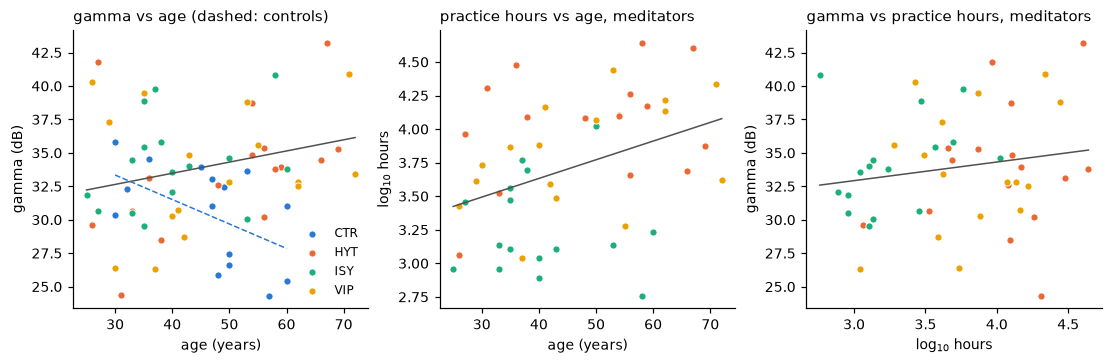

In [11]:
fig, axs = plt.subplots(1, 3, figsize=(10, 3.2), constrained_layout=True)
for ax, (x, y, xl, yl, data) in zip(axs, [
        ('age', 'gamma_paper', 'age (years)', 'gamma (dB)', zen),
        ('age', 'log_hours', 'age (years)', 'log$_{10}$ hours', med),
        ('log_hours', 'gamma_paper', 'log$_{10}$ hours', 'gamma (dB)', med)]):
    for g, d in data.groupby('group'):
        ax.scatter(d[x], d[y], s=22, color=COLOURS[g], edgecolor='white', lw=0.6, label=g)
    for sel, col in [(data.group != 'CTR', '#52514e'), (data.group == 'CTR', COLOURS['CTR'])]:
        d = data[sel].dropna(subset=[x, y])
        if len(d) > 2:
            b = np.polyfit(d[x], d[y], 1)
            xs = np.linspace(d[x].min(), d[x].max(), 20)
            ax.plot(xs, np.polyval(b, xs), color=col, lw=1, ls='-' if col != COLOURS['CTR'] else '--')
    ax.set_xlabel(xl)
    ax.set_ylabel(yl)
axs[0].set_title('gamma vs age (dashed: controls)', loc='left', fontsize=9.5)
axs[1].set_title('practice hours vs age, meditators', loc='left', fontsize=9.5)
axs[2].set_title('gamma vs practice hours, meditators', loc='left', fontsize=9.5)
axs[0].legend(frameon=False, fontsize=8)
plt.show()

## 4. Does age explain the meditator–control gamma difference?

The groups are age-matched, so adding age as a covariate cannot change the mean difference much. What could matter is
an age $\times$ group interaction: if gamma rises with age in meditators but falls in controls, the size of the group
difference depends on the age range sampled. The last cell shows the model-implied meditator–control difference
across the sampled ages.

In [12]:
allz = zen.assign(age_c=zen.age - zen.age.mean())
rows = []
for name, f in {'group only': 'gamma_paper ~ meditator',
                '+ age': 'gamma_paper ~ meditator + age_c',
                '+ age x group': 'gamma_paper ~ meditator * age_c',
                '+ age x group + gender': 'gamma_paper ~ meditator * age_c + C(gender)'}.items():
    data = allz.dropna(subset=['gender']) if 'gender' in f else allz
    fit = smf.ols(f, data).fit(cov_type='HC3')
    for term in ['meditator', 'age_c', 'meditator:age_c']:
        if term in fit.params:
            rows.append(dict(model=name, term=term, est=fit.params[term], se=fit.bse[term], p=fit.pvalues[term],
                             n=int(fit.nobs)))
print('Paper values, all 64 subjects (meditator effect at the mean age when age is in the model)')
pd.DataFrame(rows).round(3)

Paper values, all 64 subjects (meditator effect at the mean age when age is in the model)


,model,term,est,se,p,n
0,group only,meditator,3.386,1.109,0.002,64
1,+ age,meditator,3.398,1.169,0.004,64
2,+ age,age_c,0.042,0.047,0.367,64
3,+ age x group,meditator,3.355,1.033,0.001,64
4,+ age x group,age_c,-0.183,0.085,0.031,64
5,+ age x group,meditator:age_c,0.266,0.099,0.007,64
6,+ age x group + gender,meditator,3.455,1.076,0.001,63
7,+ age x group + gender,age_c,-0.178,0.088,0.042,63
8,+ age x group + gender,meditator:age_c,0.261,0.103,0.011,63


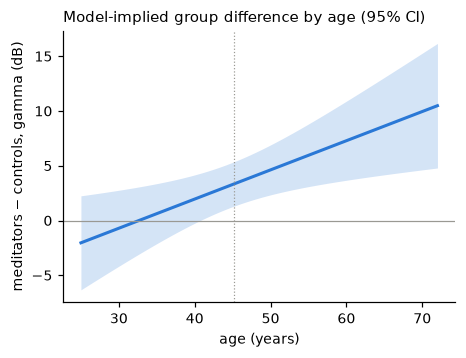

In [13]:
fit = smf.ols('gamma_paper ~ meditator * age_c', allz).fit(cov_type='HC3')
ages = np.linspace(zen.age.min(), zen.age.max(), 60)
grid = pd.DataFrame({'age_c': ages - zen.age.mean()})
diff, lo, hi = [], [], []
for a in grid.age_c:
    c = np.zeros(len(fit.params))
    c[list(fit.params.index).index('meditator')] = 1
    c[list(fit.params.index).index('meditator:age_c')] = a
    t = fit.t_test(c)
    diff.append(float(t.effect[0]))
    lo_, hi_ = t.conf_int()[0]
    lo.append(lo_)
    hi.append(hi_)
fig, ax = plt.subplots(figsize=(4.6, 3.2))
ax.fill_between(ages, lo, hi, color='#2a78d6', alpha=0.2, lw=0)
ax.plot(ages, diff, color='#2a78d6', lw=2)
ax.axhline(0, color='#9a9993', lw=0.8)
ax.axvline(zen.age.mean(), color='#9a9993', lw=0.8, ls=':')
ax.set_xlabel('age (years)')
ax.set_ylabel('meditators − controls, gamma (dB)')
ax.set_title('Model-implied group difference by age (95% CI)', loc='left', fontsize=9.5)
plt.show()

## 5. The same tests on this replication's gamma values

The paper's values come from its own pipeline. Here the gamma is this replication's trait value (mean of `med2` and
`think2` power over the 8-electrode parieto-occipital cluster, in dB), for the 63 subjects in ds003969, with
practice hours and age from the paper's file. Only differences and correlations matter, so the absolute dB offset
is irrelevant.

In [14]:
def replication_gamma(run_suffix):
    d = pd.read_csv(ROOT / f'writeup/results/matched/per_subject_vs_paper_{run_suffix}.csv', dtype={'subject': str})
    return d[(d.band == 'gamma') & (d.cond == 'trait')].set_index('subject').db


sources = {'paper values': zen.set_index('subject').gamma_paper.dropna(),
           'replication, no ICA': replication_gamma('_matchsample_noica_v0'),
           'replication, capped ICA': replication_gamma('_matchsample_v0')}
summary = []
for src, g in sources.items():
    d = zen.dropna(subset=['subject']).set_index('subject').assign(gamma=g).dropna(subset=['gamma']).reset_index()
    m = d[d.meditator == 1]
    sk = skipped_corr(m.log_hours, m.gamma)
    f_ha = smf.ols('gamma ~ log_hours + age', m).fit(cov_type='HC3')
    f_int = smf.ols('gamma ~ meditator * age_c', d.assign(age_c=d.age - d.age.mean())).fit(cov_type='HC3')
    f_grp = smf.ols('gamma ~ meditator', d).fit(cov_type='HC3')
    summary.append({
        'source': src, 'n': len(d),
        'skipped r, gamma~log hours': f"{sk['r']:.2f} [{sk['ci_low']:.2f}, {sk['ci_high']:.2f}]",
        'Spearman, gamma~age (med.)': round(stats.spearmanr(m.age, m.gamma)[0], 2),
        'Spearman, gamma~age (ctr)': round(stats.spearmanr(d[d.meditator == 0].age, d[d.meditator == 0].gamma)[0], 2),
        'p log hours | age': round(f_ha.pvalues['log_hours'], 3),
        'p age | log hours': round(f_ha.pvalues['age'], 3),
        'meditator diff (dB), p': f"{f_grp.params['meditator']:+.2f}, {f_grp.pvalues['meditator']:.3f}",
        'meditator diff at mean age | age x group, p': f"{f_int.params['meditator']:+.2f}, {f_int.pvalues['meditator']:.3f}",
        'age x group, p': f"{f_int.params['meditator:age_c']:+.3f}, {f_int.pvalues['meditator:age_c']:.3f}",
    })
pd.DataFrame(summary).set_index('source').T

source,paper values,"replication, no ICA","replication, capped ICA"
n,63,63,63
"skipped r, gamma~log hours","0.24 [-0.15, 0.49]","0.16 [-0.16, 0.51]","-0.06 [-0.33, 0.35]"
"Spearman, gamma~age (med.)",0.24,0.26,0.35
"Spearman, gamma~age (ctr)",-0.5,-0.45,-0.55
p log hours | age,0.675,0.696,0.55
p age | log hours,0.216,0.172,0.008
"meditator diff (dB), p","+3.39, 0.002","+3.13, 0.001","+2.34, 0.020"
"meditator diff at mean age | age x group, p","+3.32, 0.001","+3.09, 0.001","+2.30, 0.014"
"age x group, p","+0.268, 0.007","+0.205, 0.024","+0.256, 0.002"


## Conclusions

**Controls are not younger in the matched sample.** Controls average 45.4 years against 44.9 for meditators
($p = .93$). The young controls (mean 33.8) are the 15 the paper left out.

**Fig. 4D reproduces as a point estimate, but it is fragile.**
- The skipped correlation between gamma and log practice hours is exactly the paper's $r = 0.33$, after removing two
  bivariate outliers (HYT7, with high hours and low gamma, and ISY6, with low hours and high gamma).
- Without the outlier step, the correlation is weak: Pearson $r = 0.16$ ($p = .27$), Spearman $\rho = 0.14$.
- The CI depends on how the bootstrap treats the outliers. If the two outliers are removed once and Pearson's $r$
  is bootstrapped on the remaining 46, the CI is [0.07, 0.54], matching the paper's [0.06, 0.53]; this is evidently
  what the paper did. That CI ignores the uncertainty in which points get flagged. Redoing the outlier detection
  in each resample gives [−0.15, 0.50], which includes zero.
- Dropping HYT26 (missing from ds003969) lowers the skipped $r$ to 0.24.
- On this replication's own gamma the skipped $r$ is 0.16 without ICA and −0.06 with capped ICA.

**Age can account for the experience correlation.** Among meditators, practice hours rise with age ($r = 0.38$,
$p = .009$), and gamma tracks age ($r = 0.27$, $p = .07$) more closely than hours ($r = 0.16$). With both in the
model, the hours coefficient falls from 0.16 to 0.08 SD ($p = .69$); the partial correlation of gamma with hours
given age is 0.07. Age is not significant either ($p = .22$), so the data cannot separate the two. What they do show
is that the experience effect cannot be distinguished from age. Adding tradition fixed effects does not change this.

**Age does not explain the group difference on average, but the difference depends on age.**
- Adding age as a covariate leaves the meditator–control difference unchanged (+3.4 dB, $p = .004$), as expected
  with matched groups.
- There is an age × group interaction ($p = .007$): controls' gamma falls with age ($-0.18$ dB/year, $p = .03$),
  while meditators' rises slightly (+0.08 dB/year, $p = .10$).
- The implied difference is about +3.3 dB at the mean age of 45, significant only from about age 41, and absent
  (or reversed, not significantly) below about 35.
- The interaction holds on this replication's gamma, with and without ICA ($p = .002$–$.024$).

So the meditator advantage in gamma is concentrated in older participants and is driven mainly by older controls
having lower gamma. A cross-sectional design cannot tell whether that reflects meditation offsetting an age-related
decline, or differences in who was recruited. The control slope rests on 16 people, 5 of them aged 36 or under.
